<a href="https://colab.research.google.com/github/Existanze54/sirius-machine-learning-2026/blob/main/Homeworks/HW1_Numpy_Pandas_Mpl.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Домашка 1. Основы анализа данных с Python

#### Заметка о Google Colab

Напомню, что мы работаем в **Google Colab**, который представляет собой удобную оболочку для **Jupyter Notebook**. Ядро `python` запускается на серверах **Google**. Поддерживаются также `R` и `Julia`. Из ноутбука можно устанавливать любые пакеты, но главное преимущество **Colab** — большинство библиотек для анализа данных предустановлено.  
  
Ноутбук состоит из ячеек двух типов: код и текст. Текстовые ячейки поддерживают Markdown. Для редактирования используется *режим редактирования* (**Enter** на выбранной ячейке). Для навигации — *командный режим* (**Esc**).  
  
После ввода содержимого выполните *Shift+Enter*: код будет запущен, текст — отрендерен, а курсор перейдёт к следующей ячейке. Полный список сочетаний клавиш (и настройку собственных) можно открыть через *Ctrl+M*, затем *H*, или через меню *Tools*.

#### Заметка о разметке Markdown.

Он позволяет:
* Составлять неупорядоченные списки
1. Составлять упорядоченные списки
2. *Выделять* **текст** <s>при</s> `необходимости`
3. Добавлять [ссылки](https://c.tenor.com/o656qFKDzeUAAAAd/tenor.gif)

Форматировать формулы с $\LaTeX$:
$$\int_{-\infty}^{\infty} e^{-x^2}\,dx = \sqrt{\pi}$$

Форматировать таблички:
| Модель | Параметры | Скорость | Требование к памяти |
|--------|-----------|----------|----------------------|
| kNN    | k=5       | низкая   | высокое              |
| SVM    | C=1.0     | средняя  | среднее              |
| Ridge  | alpha=1.0 | высокая  | низкое               |
  
И даже вставлять картинки, гифки и пр.:  
<img src="https://images.onwardstate.com/uploads/2016/05/giphy-gif-11.gif" width='300'>

## Задача 1. NumPy

Незнайка любит поспать и обычно пропускает лекции по молекулярной биологии, так что за курс он набрал 5 баллов по посещениям. Несколько практических работ он тоже пропустил, так что всего набрал 6 баллов за них. Но котелок у Незнайки варит, и он может когда захочет: за домашки и финальный экзамен он получил 9 и 10 соответственно. Какую оценку ему должен поставить преподаватель, если экзамен, домашки, практики и посещяемость имеют веса [0.5, 0.3, 0.1, 0.1] соответсвенно?  
  
Решите задачу с попомщью обычного оператора `*` и метода `.sum`, а так же с помощью скалярного произведения `.dot`. Сравните скорость, используя команду `%%timeit`.

In [112]:
import numpy as np

marks = [10, 9, 6, 5]
weights = [0.5, 0.3, 0.1, 0.1]

am = np.array(marks)
aw = np.array(weights)

In [113]:
np.dot(marks, weights), (am * aw).sum()


(np.float64(8.8), np.float64(8.799999999999999))

In [114]:
%%timeit
(am * aw).sum()


3.24 μs ± 239 ns per loop (mean ± std. dev. of 7 runs, 100,000 loops each)


In [115]:
%%timeit
b = np.dot(marks, weights)

2.77 μs ± 386 ns per loop (mean ± std. dev. of 7 runs, 100,000 loops each)


## Задача 2. Pandas

Для данной задачи импортируем учебный датасет с помощью библиотеки `seaborn` — это наворочанная версия `matplotlib`.

In [116]:
import pandas as pd
import seaborn as sns
df = sns.load_dataset('penguins')

Перед обучением модели обычно нужно подготовить данные: масштабировать вещественные признаки и закодировать категориальные. Чаще всего для этого используют удобные функции и классы библиотеки `sklearn`, но так ли сложно обойтись без нее? В этом задании вам предстоит подготовить данные, используя только методы и функции `pandas`.  
  
Для начала разделите датафрейм на два — с категориальными и числовыми признаками (извлечь несколько колонок можно так: `df[['island', 'sex']]`). Категориальные признаки закодируйте унитарным (one-hot) кодированием с помощью `pd.get_dummies`. Числовые признаки стандартизируйте, используя методы `.mean()` и `.std()`, по формуле
$$
x_{i,\text{scaled}} = \frac{x_i - \mu(x)}{\sigma(x)}
$$
После этого объедините все признаки функцией `pd.concat` и сохраните результат с помощью `.to_csv`.
  
Если в датасете есть измерения с пропущенными значениями, избавьтесь от них.

In [117]:
# your code here

df = df.dropna()
df_cot = df[["species", "island", "sex"]]
df_num = df[["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]]


In [118]:
df_num_scaled = (df_num - df_num.mean()) / df_num.std()
df_cat_d = pd.get_dummies(df_cot)

final = pd.concat([df_num_scaled, df_cat_d], axis=1)
final.to_csv('penguins.csv', index=False, encoding='utf-8')
final.head()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,species_Adelie,species_Chinstrap,species_Gentoo,island_Biscoe,island_Dream,island_Torgersen,sex_Female,sex_Male
0,-0.894695,0.779559,-1.424608,-0.567621,True,False,False,False,False,True,False,True
1,-0.821552,0.119404,-1.067867,-0.505525,True,False,False,False,False,True,True,False
2,-0.675264,0.424091,-0.425733,-1.188572,True,False,False,False,False,True,True,False
4,-1.333559,1.084246,-0.568429,-0.940192,True,False,False,False,False,True,True,False
5,-0.858123,1.744400,-0.782474,-0.691811,True,False,False,False,False,True,False,True


In [121]:
final = final.astype(float)

In [122]:
final.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
bill_length_mm,333.0,0.00,1.00,-2.17,-0.82,0.09,0.84,2.85
bill_depth_mm,333.0,0.00,1.00,-2.06,-0.79,0.07,0.78,2.20
flipper_length_mm,333.0,0.00,1.00,-2.07,-0.78,-0.28,0.86,2.14
body_mass_g,333.0,-0.00,1.00,-1.87,-0.82,-0.20,0.71,2.60
species_Adelie,333.0,0.44,0.50,0.00,0.00,0.00,1.00,1.00
species_Chinstrap,333.0,0.20,0.40,0.00,0.00,0.00,0.00,1.00
species_Gentoo,333.0,0.36,0.48,0.00,0.00,0.00,1.00,1.00
island_Biscoe,333.0,0.49,0.50,0.00,0.00,0.00,1.00,1.00
island_Dream,333.0,0.37,0.48,0.00,0.00,0.00,1.00,1.00
island_Torgersen,333.0,0.14,0.35,0.00,0.00,0.00,0.00,1.00


## Часть 3. Matplotlib

Используйте данные из предыдущей задачи. На первом графике постройте распределение массы тела по полу птицы (две гистограммы). На втором — распределение длины крыла (плавника) по видам (три гистограммы). Добавьте заголовки с помощью `plt.title`, подпишите оси через `plt.xlabel` и `plt.ylabel`, обозначьте категории функцией `plt.legend`. Сохраните результат в файл `.png` с разрешением 150 dpi, используя `plt.savefig`.


In [51]:
import matplotlib.pyplot as plt

# Бонус: можно поиграться со стилями из seaborn,
# чтобы графики выглядели симпатичнее "из коробки"
sns.set_style('whitegrid')

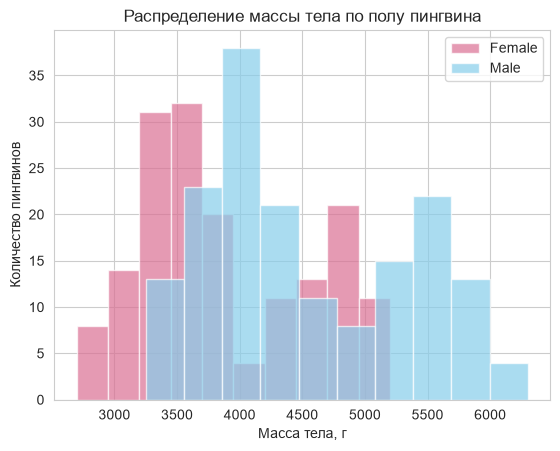

In [85]:
# your code here

fem = df[df["sex"] == "Female"]
male = df[df["sex"] == "Male"]

plt.hist(fem["body_mass_g"], color="palevioletred", label="Female", alpha=0.7)
plt.hist(male["body_mass_g"], color="skyblue", label="Male", alpha=0.7)
plt.title("Распределение массы тела по полу пингвина")
plt.xlabel("Масса тела, г")
plt.ylabel("Количество пингвинов")
plt.legend()

plt.savefig("body_mass_by_sex.png", dpi=150, bbox_inches="tight")
plt.show()

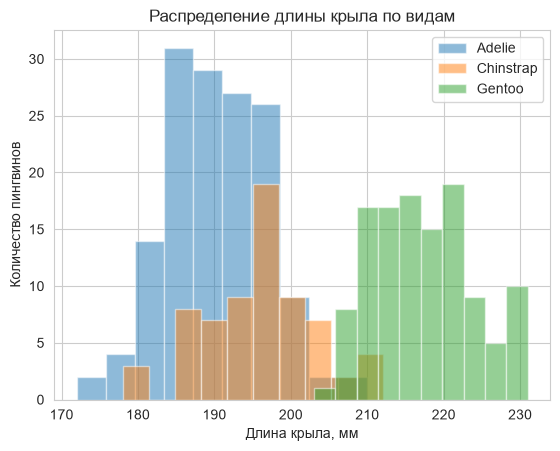

In [86]:
for sp in df["species"].unique():
    sub_set = df[df["species"] == sp]
    plt.hist(sub_set["flipper_length_mm"], label=sp, alpha=0.5)
    

plt.title("Распределение длины крыла по видам")
plt.xlabel("Длина крыла, мм")
plt.ylabel("Количество пингвинов")
plt.legend()

plt.savefig("flipper_length_by_species.png", dpi=150, bbox_inches="tight")
plt.show()